In [1]:
import sys
from pathlib import Path
root_dir = Path().resolve().parent
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

from src.plot_utils import setup_plot_style
import src.stats_utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Setup default plotting style
setup_plot_style()

PYTHON_PATH ="C:/Users/Admin/Documents/GitHub/Statistiek/Python/"
FIGURE_PATH = PYTHON_PATH + "Figures/"
DATA_PATH = PYTHON_PATH + "data/"

# Datavisualisation: Florence nightingale

In [3]:
# Use a stable mirror URL for the Nightingale dataset
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/HistData/Nightingale.csv"
df_coxcomb = pd.read_csv(url)

print(df_coxcomb.head())

   rownames        Date Month  Year   Army  Disease  Wounds  Other  \
0         1  1854-04-01   Apr  1854   8571        1       0      5   
1         2  1854-05-01   May  1854  23333       12       0      9   
2         3  1854-06-01   Jun  1854  28333       11       0      6   
3         4  1854-07-01   Jul  1854  28722      359       0     23   
4         5  1854-08-01   Aug  1854  30246      828       1     30   

   Disease.rate  Wounds.rate  Other.rate  
0           1.4          0.0         7.0  
1           6.2          0.0         4.6  
2           4.7          0.0         2.5  
3         150.0          0.0         9.6  
4         328.5          0.4        11.9  


In [4]:
df_coxcomb["MonthYear"] =  df_coxcomb['Month'].astype(str) + " " + df_coxcomb['Year'].astype(str)
df_coxcomb.rename(columns={"Disease": "Deaths from Preventible Disease", "Wounds": "Deaths from Wounds", "Other": "Deaths from Other Causes"}, inplace=True)
df_coxcomb["Deaths from Preventible Disease"]

0        1
1       12
2       11
3      359
4      828
5      788
6      503
7      844
8     1725
9     2761
10    2120
11    1205
12     477
13     508
14     802
15     382
16     483
17     189
18     128
19     178
20      91
21      42
22      24
23      15
Name: Deaths from Preventible Disease, dtype: int64

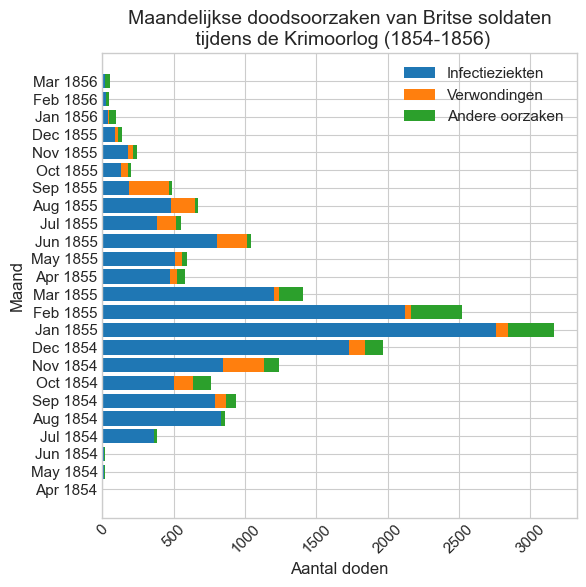

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Monthly Crimean War mortality data (approximate, widely used for teaching)
months = [
    "Apr 1854","May 1854","Jun 1854","Jul 1854","Aug 1854","Sep 1854",
    "Oct 1854","Nov 1854","Dec 1854","Jan 1855","Feb 1855","Mar 1855",
    "Apr 1855","May 1855","Jun 1855","Jul 1855","Aug 1855","Sep 1855",
    "Oct 1855","Nov 1855","Dec 1855","Jan 1856","Feb 1856","Mar 1856"
]

disease = df_coxcomb["Deaths from Preventible Disease"]
wounds = df_coxcomb["Deaths from Wounds"]
other = df_coxcomb["Deaths from Other Causes"]

df = pd.DataFrame({
    "Maand": months,
    "Infectieziekten": disease,
    "Verwondingen": wounds,
    "Andere oorzaken": other
})

# Plot stacked bar chart
plt.figure(figsize=(6, 6))
plt.barh(df["Maand"], df["Infectieziekten"], label="Infectieziekten")
plt.barh(df["Maand"], df["Verwondingen"], left=df["Infectieziekten"], label="Verwondingen")
plt.barh(
    df["Maand"],
    df["Andere oorzaken"],
    left=df["Infectieziekten"] + df["Verwondingen"],
    label="Andere oorzaken"
)

plt.ylabel("Maand")
plt.xlabel("Aantal doden")
plt.title("Maandelijkse doodsoorzaken van Britse soldaten\n tijdens de Krimoorlog (1854-1856)")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.savefig(FIGURE_PATH+"stacked_barchart_florence_nightingale.png")


# Unit readiness levels

In [7]:
df = pd.read_csv("../data/unit_readiness_levels.csv")

df_reduced = df[["type_eenheid", "personeelssterkte_pct", "opleiding_voltooid_pct", "materieel_beschikbaarheid_pct", "onderhoud_status", "logistiek_niveau", "inzetstatus", "gereedheid_H1_score"]].head()
df_reduced.reset_index(drop=True, inplace=True)
df_reduced

,type_eenheid,personeelssterkte_pct,opleiding_voltooid_pct,materieel_beschikbaarheid_pct,onderhoud_status,logistiek_niveau,inzetstatus,gereedheid_H1_score
0,Infanterie,92,88,85,Goed,Hoog,Stand-by,86
1,Artillerie,85,82,80,Goed,Medium,Stand-by,80
2,Genie,78,75,70,Matig,Medium,Inzet,70
3,Luchtmobiel,90,90,88,Onvoldoende,Hoog,Stand-by,85
4,Logistiek,95,92,93,Uitstekend,Hoog,Reserve,92


# Frequentietabel

In [9]:
# Frequentietabel
frequentie = df["onderhoud_status"].value_counts()
print(frequentie)

onderhoud_status
Goed           43
Uitstekend     39
Matig          27
Onvoldoende    16
Name: count, dtype: int64


# Kruistabel

In [11]:
kruistabel_inzet = pd.crosstab(
    df["type_eenheid"],
    df["onderhoud_status"]
)

print(kruistabel_inzet)

onderhoud_status     Goed  Matig  Onvoldoende  Uitstekend
type_eenheid                                             
Artillerie              9     10            3           0
Geneeskundige keten     0      0            0          20
Genie                   7     10            3           0
Infanterie             12      7            4           0
Logistiek               0      0            1          19
Luchtmobiel            15      0            5           0


# Staafdiagram

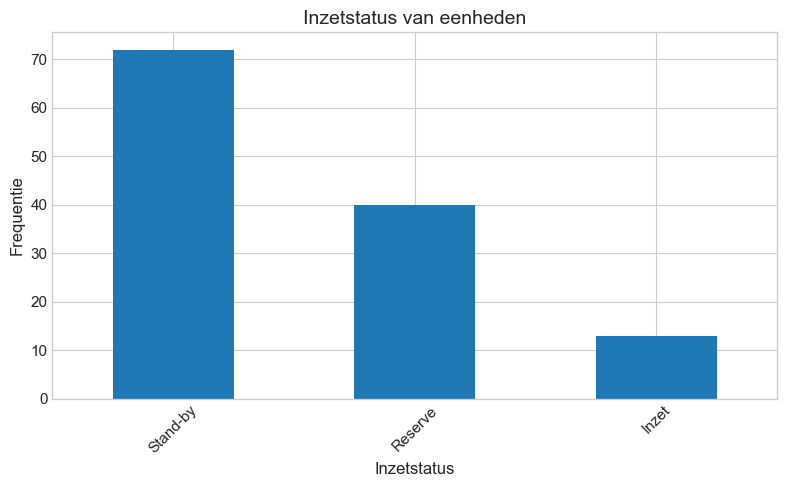

In [13]:
# Dataset inlezen
df = pd.read_csv(DATA_PATH + "unit_readiness_levels.csv")

# Frequenties tellen
frequenties = df["inzetstatus"].value_counts()

# Staafdiagram
plt.figure()
frequenties.plot(kind="bar")
plt.xlabel("Inzetstatus")
plt.ylabel("Frequentie")
plt.title("Inzetstatus van eenheden")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(FIGURE_PATH+"staafdiagram.png")

# Cirkeldiagram

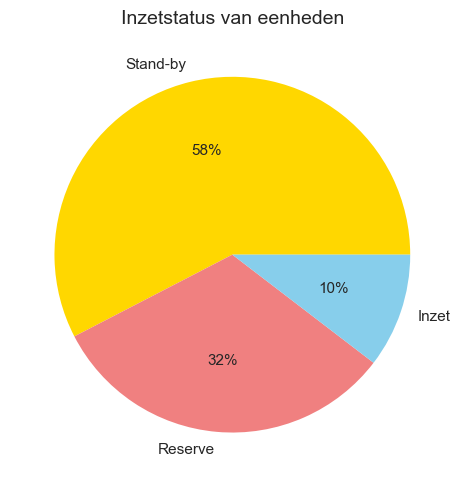

In [15]:
# --------------------------------------------------
# Pie chart: Inzetstatus
# --------------------------------------------------
deploy_counts = df["inzetstatus"].value_counts()
plt.figure()
plt.pie(deploy_counts, labels=deploy_counts.index, autopct="%1.0f%%", colors=["gold","lightcoral","skyblue"])
plt.title("Inzetstatus van eenheden")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_PATH+"cirkeldiagram.png")

# Gestapelde staafdiagram

<Figure size 800x500 with 0 Axes>

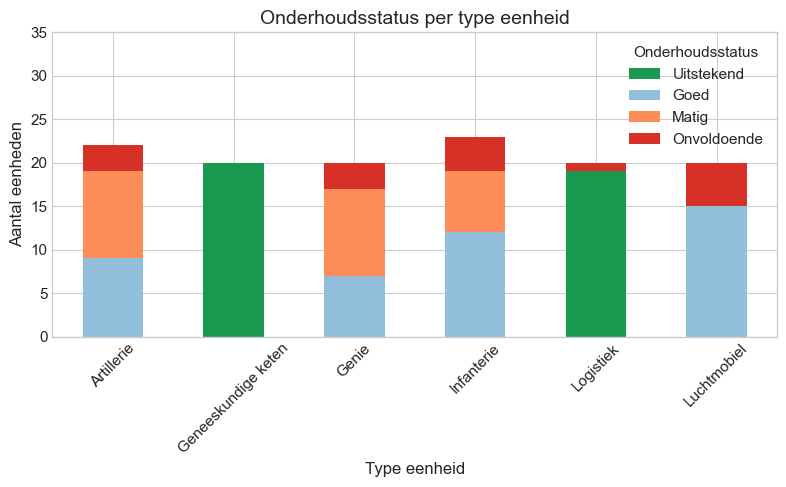

In [17]:
# Dataset inlezen
df = pd.read_csv("../data/unit_readiness_levels.csv")

# Kruistabel maken
kruistabel_onderhoud = pd.crosstab(
    df["type_eenheid"],
    df["onderhoud_status"]
)

# Logische volgorde van onderhoudsstatus
kleuren = {
    "Uitstekend": "#1a9850",   # groen
    "Goed": "#91bfdb",         # lichtblauw
    "Matig": "#fc8d59",        # oranje
    "Onvoldoende": "#d73027"   # rood
}

kruistabel_onderhoud = kruistabel_onderhoud[kleuren.keys()]

# Gestapeld staafdiagram
plt.figure()
kruistabel_onderhoud.plot(
    kind="bar",
    stacked=True,
    color=[kleuren[k] for k in kruistabel_onderhoud.columns]
)

plt.xlabel("Type eenheid")
plt.ylabel("Aantal eenheden")
plt.title("Onderhoudsstatus per type eenheid")
plt.legend(title="Onderhoudsstatus")
plt.xticks(rotation=45)
plt.ylim(top=35)
plt.tight_layout()
plt.savefig(FIGURE_PATH+"gestapelde_staafdiagram.png")

# Histogram

0      0.008502
1      0.016411
2      0.023332
3      0.031735
4      0.040830
         ...   
120    0.966387
121    0.974790
122    0.983688
123    0.992882
124    1.000000
Name: gereedheid_H1_score, Length: 125, dtype: float64


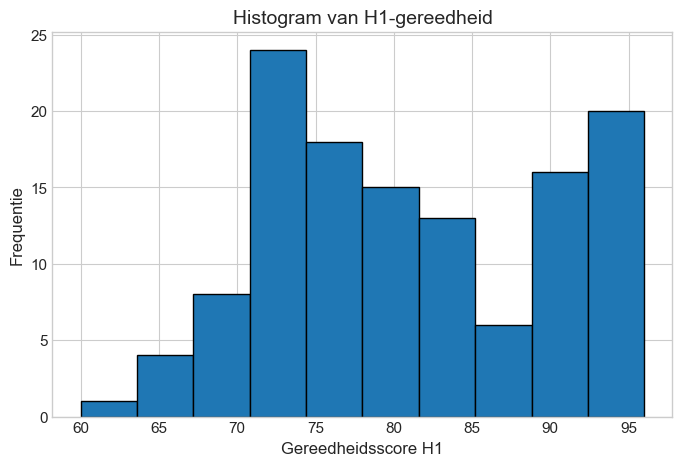

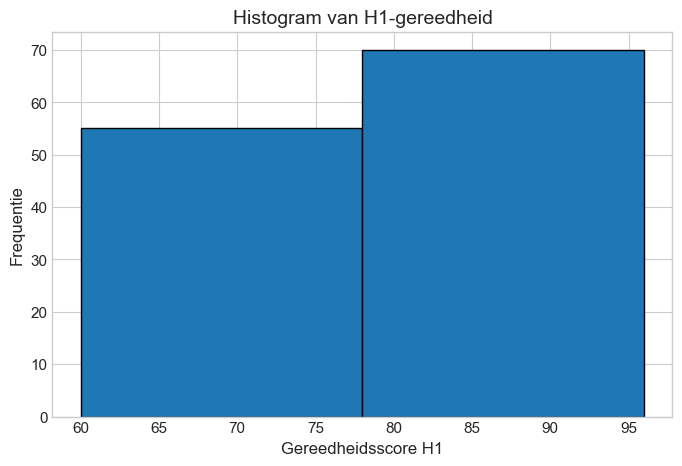

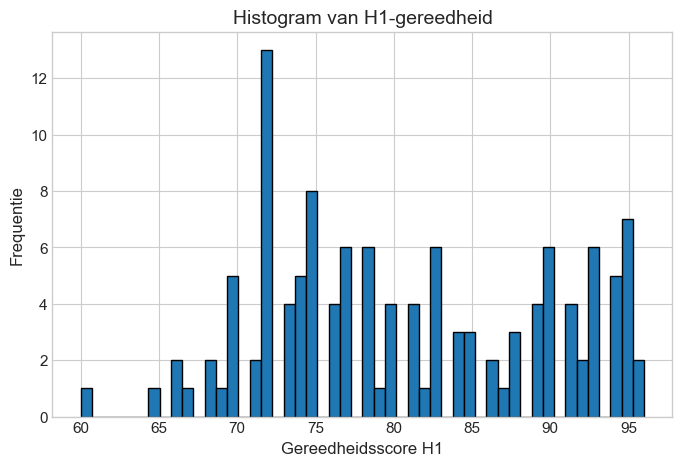

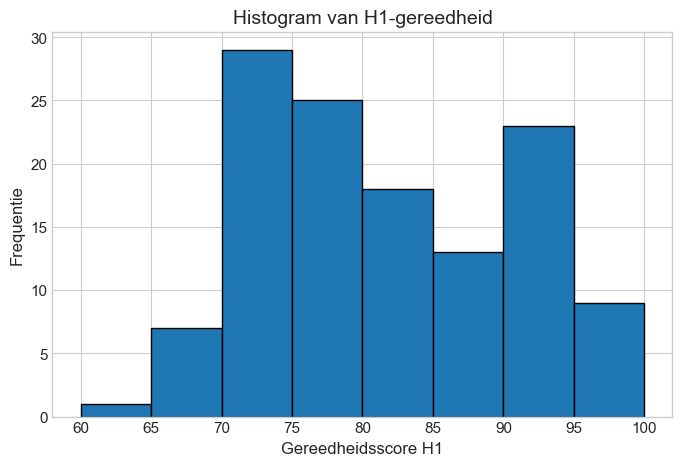

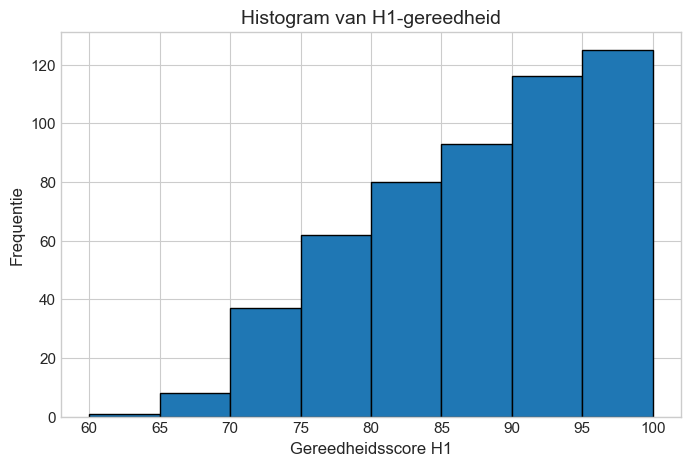

In [19]:
# Dataset inlezen
df = pd.read_csv(DATA_PATH+"unit_readiness_levels.csv")

scores = df["gereedheid_H1_score"]
relative_cumulative_scores = scores.cumsum() / scores.sum()
print(relative_cumulative_scores)

plt.figure()
plt.hist(scores, bins=10, edgecolor="black", linewidth=1)
plt.xlabel("Gereedheidsscore H1")
plt.ylabel("Frequentie")
plt.title("Histogram van H1-gereedheid")
plt.savefig(FIGURE_PATH+"histogram.png")

# Te weinig bins
plt.figure()
plt.hist(scores, bins=2, edgecolor="black", linewidth=1)
plt.xlabel("Gereedheidsscore H1")
plt.ylabel("Frequentie")
plt.title("Histogram van H1-gereedheid")
plt.savefig(FIGURE_PATH+"histogram_toofew.png")

# Te veel bins
plt.figure()
plt.hist(scores, bins=50, edgecolor="black", linewidth=1)
plt.xlabel("Gereedheidsscore H1")
plt.ylabel("Frequentie")
plt.title("Histogram van H1-gereedheid")
plt.savefig(FIGURE_PATH+"histogram_toomany.png")

# Just right
plt.figure()
plt.hist(scores, bins=[60, 65, 70, 75, 80, 85, 90, 95, 100], edgecolor="black", linewidth=1)
plt.xlabel("Gereedheidsscore H1")
plt.ylabel("Frequentie")
plt.title("Histogram van H1-gereedheid")
plt.savefig(FIGURE_PATH+"histogram_justright.png")

# Cumulative histogram
plt.figure()
plt.hist(scores, bins=[60, 65, 70, 75, 80, 85, 90, 95, 100], cumulative=True, edgecolor="black", linewidth=1)
plt.xlabel("Gereedheidsscore H1")
plt.ylabel("Frequentie")
plt.title("Histogram van H1-gereedheid")
plt.savefig(FIGURE_PATH+"cumulative_justright.png")


In [20]:
# Define bins and labels
bins = list(range(60, 105, 5))  # 60, 65, ..., 100
labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins) - 1)]

# Discretize scores
df["gereedheid_klasse"] = pd.cut(
    df["gereedheid_H1_score"],
    bins=bins,
    labels=labels,
    right=False  # intervals are [60–65), [65–70), ...
)

# Frequency table
frequentietabel = df["gereedheid_klasse"].value_counts().sort_index()

# Cumulatieve relatieve frequentieverdeling

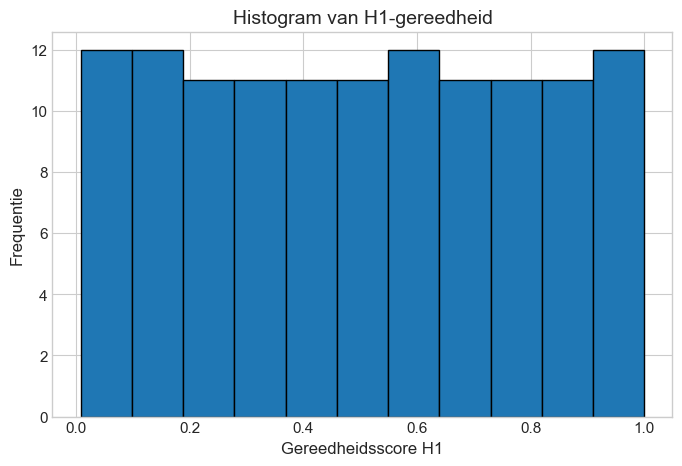

In [22]:
# Dataset inlezen
df = pd.read_csv(DATA_PATH+"unit_readiness_levels.csv")

scores = df["gereedheid_H1_score"]

# Just right
plt.figure()
plt.hist(relative_cumulative_scores, bins=int(np.sqrt(df.shape[0])), edgecolor="black", linewidth=1)
plt.xlabel("Gereedheidsscore H1")
plt.ylabel("Frequentie")
plt.title("Histogram van H1-gereedheid")
plt.savefig(FIGURE_PATH+"histogram_justright.png")


# Scatter plot (spreidingsdiagram)

    eenheid_id         type_eenheid  personeelssterkte_pct  \
0         E001           Infanterie                     92   
1         E002           Artillerie                     85   
2         E003                Genie                     78   
3         E004          Luchtmobiel                     90   
4         E005            Logistiek                     95   
..         ...                  ...                    ...   
120       E121                Genie                     80   
121       E122          Luchtmobiel                     89   
122       E123            Logistiek                     92   
123       E124  Geneeskundige keten                     95   
124       E125           Infanterie                     78   

     opleiding_voltooid_pct  materieel_beschikbaarheid_pct onderhoud_status  \
0                        88                             85             Goed   
1                        82                             80             Goed   
2                 

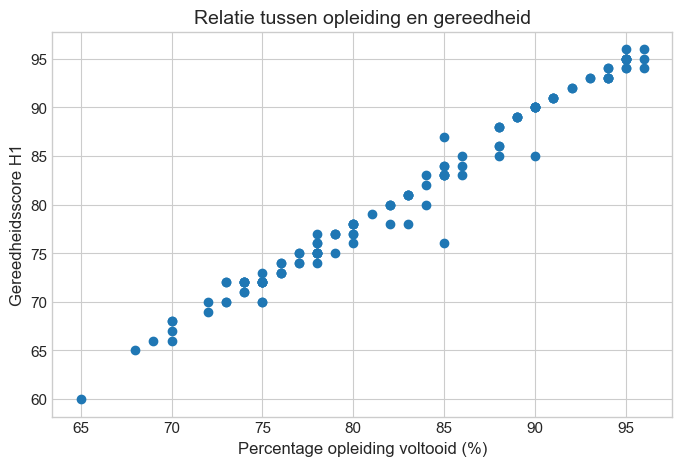

In [24]:
# Scatterplot
print(df)
plt.figure()
plt.scatter(
    df["opleiding_voltooid_pct"],
    df["gereedheid_H1_score"]
)

plt.xlabel("Percentage opleiding voltooid (%)")
plt.ylabel("Gereedheidsscore H1")
plt.title("Relatie tussen opleiding en gereedheid")
plt.savefig(FIGURE_PATH+"scatterplot.png")

In [25]:
df[["opleiding_voltooid_pct", "gereedheid_H1_score"]]

,opleiding_voltooid_pct,gereedheid_H1_score
0,88,86
1,82,80
2,75,70
3,90,85
4,92,92
...,...,...
120,76,73
121,86,85
122,90,90
123,94,93


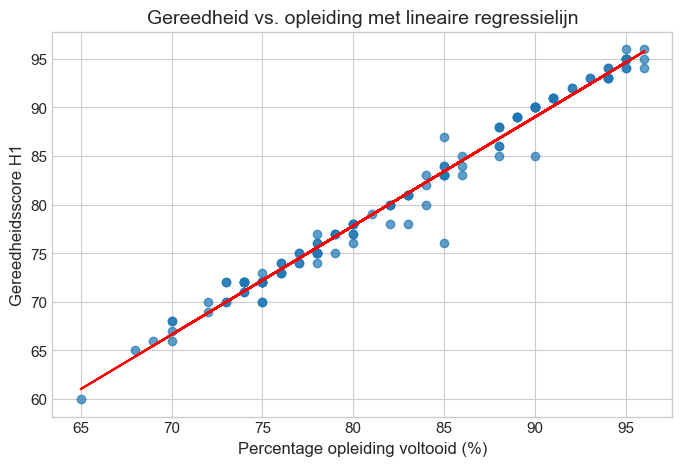

In [26]:
x = df["opleiding_voltooid_pct"]
y = df["gereedheid_H1_score"]

# Fit linear regression
coef = np.polyfit(x, y, 1)
lijn = np.poly1d(coef)

# Scatterplot
plt.figure()
plt.scatter(x, y, alpha=0.7)
plt.plot(x, lijn(x), color="red")

plt.xlabel("Percentage opleiding voltooid (%)")
plt.ylabel("Gereedheidsscore H1")
plt.title("Gereedheid vs. opleiding met lineaire regressielijn")
plt.savefig(FIGURE_PATH+"scatterplot_regression.png")

# Boxplot

['Infanterie', 'Artillerie', 'Genie', 'Luchtmobiel', 'Logistiek', 'Geneeskundige keten']


C:\Users\Admin\AppData\Local\Temp\ipykernel_13120\2397916255.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = ax.boxplot(


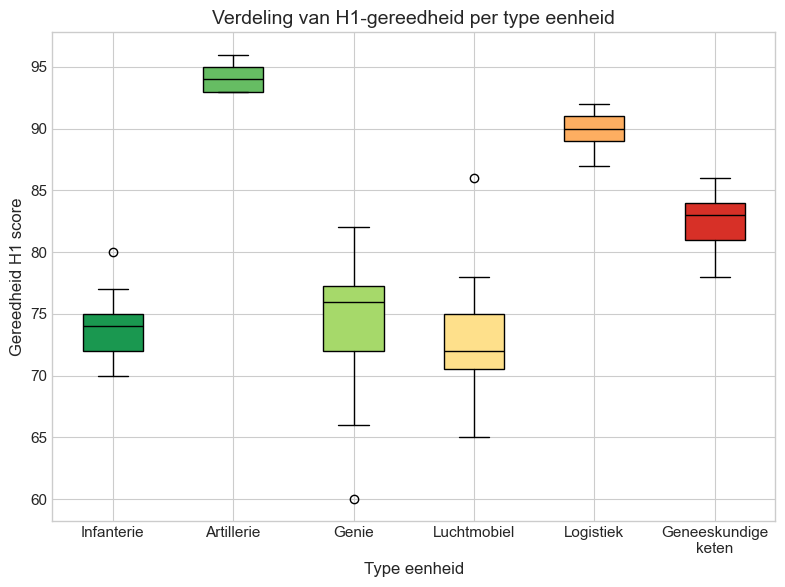

In [28]:
# Order unit types by median readiness
volgorde = list(
    df.groupby("type_eenheid")["gereedheid_H1_score"]
    .median()
    .sort_values()
    .index
)
print(volgorde)

# Group our dataset with our variable "type_eenheid"
grouped = df.groupby("type_eenheid")["gereedheid_H1_score"]

# Initialize a figure and axes
fig, ax = plt.subplots(figsize=(8,6))

# Create the boxplots with different colors for each group
boxplot = ax.boxplot(
    x=[group.values for name, group in grouped],
    labels=volgorde, 
    patch_artist=True,
    medianprops={'color': 'black'}
)

colors = [
    "#1a9850", "#66bd63", "#a6d96a",
    "#fee08b", "#fdae61", "#d73027"
]

# Assign colors to each box in the boxplot
for box, color in zip(boxplot['boxes'], colors):
    box.set_facecolor(color)

ax.set_xlabel("Type eenheid")
ax.set_ylabel("Gereedheid H1 score")
ax.set_title("Verdeling van H1-gereedheid per type eenheid")
ax.xaxis.set_ticks(ticks=[1,2,3,4,5,6], labels=volgorde[:-1] + ["Geneeskundige\nketen"])
# plt.xticks(rotation=45)
plt.tight_layout()

# Display it
plt.savefig(FIGURE_PATH+"boxplot.png")